In [1]:
import h5py
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
import numpy as np
import json

In [2]:
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/cr_bowshock_outputs"
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

ISM-v30


IndexError: boolean index did not match indexed array along dimension 0; dimension is 150 but corresponding boolean dimension is 96

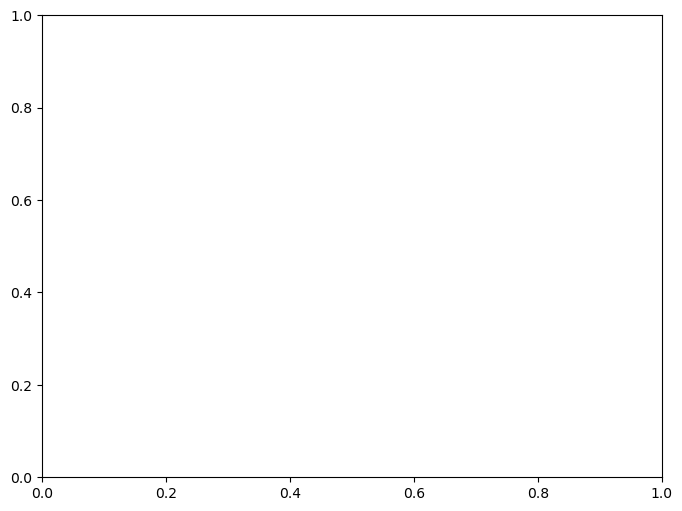

In [3]:
fig_tseries, ax_tseries = plt.subplots(figsize=(8,6))

synch_freq = 1.4 * u.GHz  # choice of synchrotron frequency

for i, sim_name in enumerate(list(bowshock_config.keys())):
    print(sim_name)
    if sim_name == "ISM-v30-Bx":
        continue

# write data to h5py file
    with h5py.File(f"{data_dir}/emission_data.h5", "r") as pf:
        times = pf[sim_name]["times"][()]
        synch_freq_grid = pf[sim_name]["synch_freq"][()] * u.GHz

        synch_lum = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)

    synch_freq_idx = np.digitize(synch_freq, synch_freq_grid, right=True)
    synch_lum = synch_lum[:,synch_freq_idx]

    times = times[synch_lum > 0]
    synch_lum = synch_lum[synch_lum > 0]

    ax_tseries.semilogy(times, synch_lum, color=bowshock_config[sim_name]["color"], label=sim_name)

ax_tseries.set_xlabel("Time / kyr", fontsize=16)
ax_tseries.set_ylabel(r"$L_\mathrm{1.4 GHz}$ / erg s$^{-1}$ Hz$^{-1}$", fontsize=16)

# ylimits
# ax_tseries.set_ylim(ymin=1e18, ymax=1e23)

# ticks
ax_tseries.tick_params(axis='both', direction="in", which='major', size=8, labelsize=18)
ax_tseries.tick_params(axis='both', direction="in", which='minor', size=6, labelsize=16)

ax_tseries.legend(prop={"size":14}, bbox_to_anchor=[0.6,1.0])

# save
fig_tseries.savefig(f"{fig_dir}/synch/synch_lum_timeseries.pdf", bbox_inches="tight", dpi=300)

Plot luminosity vs frequency and compare with observations

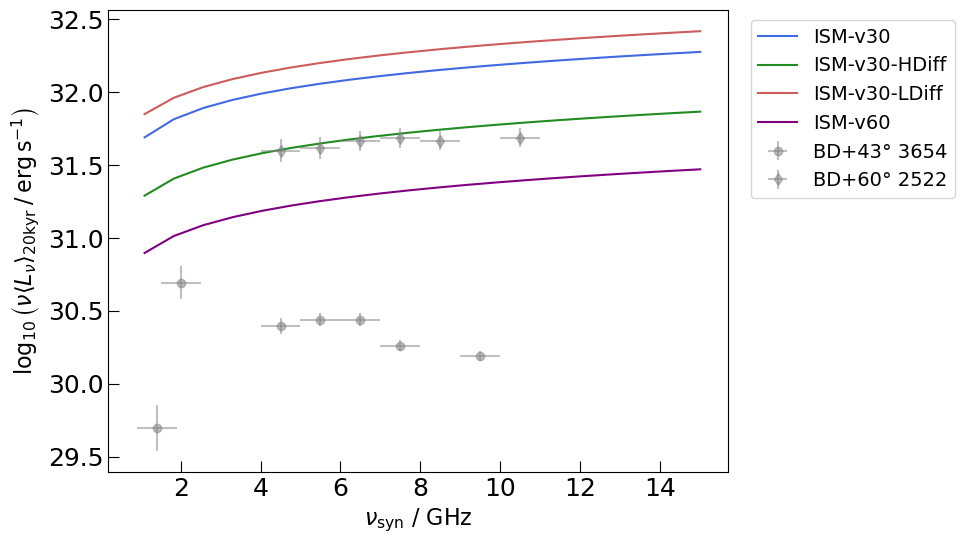

In [4]:
fig_tseries, ax_tseries = plt.subplots(figsize=(8,6))

for i, sim_name in enumerate(list(bowshock_config.keys())):
    if sim_name == "ISM-v30-Bx":
        continue

    # read data from h5py file
    with h5py.File(f"{data_dir}/emission_data.h5", "r") as pf:
        times = pf[sim_name]["times"][()] * u.kyr
        synch_lum = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)
        synch_freq_grid = pf[sim_name]["synch_freq"][()] * u.GHz

    # take the temporal average from 50 kyr or so
    tstart_idx = np.digitize(20 * u.kyr, times[:-1], right=True)
    synch_lum_tavg = np.mean(synch_lum[tstart_idx:], axis=0)

    ax_tseries.plot(synch_freq_grid, np.log10((synch_freq_grid.to(u.Hz) * synch_lum_tavg).to_value(u.erg / u.s)), color=bowshock_config[sim_name]["color"], label=sim_name)

# plot data also
data_colors = ["gray", "gray"]
data_symbols = ["o", "d"]
data_labels = ["BD+43° 3654", "BD+60° 2522"]
with h5py.File(f"{data_dir}/M22_data.h5", "r") as pf:
    for l, (bs_name, vd) in enumerate(list(pf.items())):
        synch_freq_data = vd["freq"][()] * u.GHz
        freq_err = 0.5 * u.GHz  # width of each sub-band
        d, d_err = vd["D"][()] * u.kpc
        flux =  vd["flux"][()] * 1e-12 * (u.erg * u.s**-1 * u.cm**-2)
        # pure flux is 5% calibration uncertainty, but data is nu * flux so we have to include 
        # frequency error for flux error calculation
        flux_err = flux * np.sqrt(0.05**2 + (freq_err / synch_freq_data)**2)

        # calcualte luminosity 
        synch_lum_data = (4 * np.pi * d**2 * flux).to(u.erg * u.s**-1)
        synch_lum_data_err = (4 * np.pi * np.sqrt((2 * d * flux * d_err)**2 + (d**2 * flux_err)**2)).to(u.erg * u.s**-1)

        log10_synch_lum_data = np.log10(synch_lum_data.value)
        log10_synch_lum_data_err = (synch_lum_data_err / (np.log(10) * synch_lum_data)).value

        ax_tseries.errorbar(synch_freq_data, log10_synch_lum_data, xerr = freq_err, yerr = log10_synch_lum_data_err, label=data_labels[l], marker=data_symbols[l], alpha=0.5, ls="", color=data_colors[l])

ax_tseries.set_xlabel(r"$\nu_\mathrm{syn}$ / GHz", fontsize=16)
ax_tseries.set_ylabel(r"$\log_{10}\left(\nu \langle L_\nu \rangle_\mathrm{20 kyr} \: / \: \mathrm{erg} \, \mathrm{s}^{-1} \right)$", fontsize=16)

# ylimits
# ax_tseries.set_ylim(ymin=1e18, ymax=1e23)

# ticks
ax_tseries.tick_params(axis='both', direction="in", which='major', size=8, labelsize=18)
ax_tseries.tick_params(axis='both', direction="in", which='minor', size=6, labelsize=16)

ax_tseries.legend(prop={"size":14}, bbox_to_anchor=[1.02,1.0])

fig_tseries.savefig(f"{fig_dir}/synch/synch_lum_freq.pdf", bbox_inches="tight", dpi=300)

Plot gamma ray luminosity

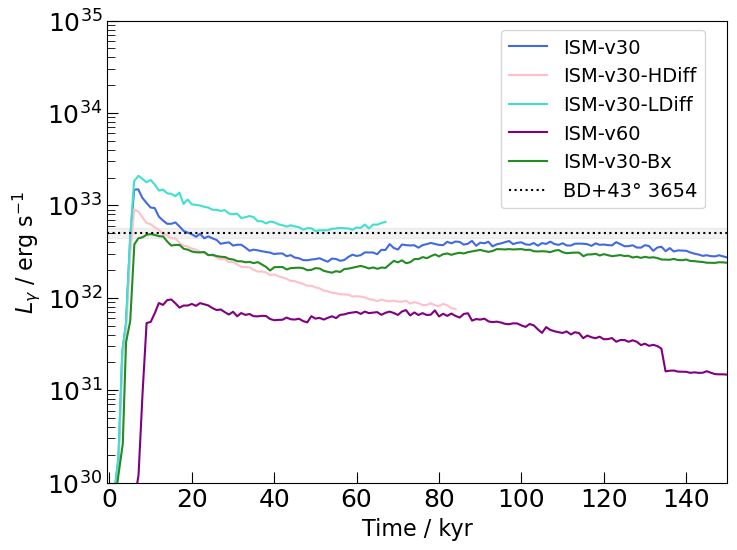

In [6]:
fig_tseries, ax_tseries = plt.subplots(figsize=(8,6))

for i, sim_name in enumerate(list(bowshock_config.keys())):

    if sim_name == "ISM-v100" or sim_name == "CMZ-v30":
        continue

# write data to h5py file
    with h5py.File(f"{data_dir}/emission_data.h5", "r") as pf:
        times = pf[sim_name]["times"][()]
        gamma_lum = pf[sim_name]["gamma_lum"][()] * u.erg * u.s**-1

    # remove outliers
    times = times[gamma_lum > 10 * u.erg * u.s**-1]
    gamma_lum = gamma_lum[gamma_lum > 10 * u.erg * u.s**-1]

    ax_tseries.semilogy(times[np.argsort(times)], gamma_lum[np.argsort(times)], color=bowshock_config[sim_name]["color"], label=sim_name)

# plot data also
with h5py.File(f"{data_dir}/S14_data.h5", "r") as pf:
    for l, (bs_name, vd) in enumerate(list(pf.items())):
        d, d_err = vd["D"][()] * u.kpc
        flux =  vd["flux"][()] * 1e-12 * (u.erg * u.s**-1 * u.cm**-2)
        flux_err = 0.05 * flux  # 5% calibration uncertainty

        # calcualte luminosity 
        gamma_lum_data = (4 * np.pi * d**2 * flux).to(u.erg * u.s**-1)
        gamma_lum_data_err = 4 * np.pi * np.sqrt((2 * d * flux * d_err)**2 + (d**2 * flux_err)**2)

        mean_gamma_lum_data = np.mean(gamma_lum_data)
        mean_gamma_lum_data_err = np.sqrt(np.sum(gamma_lum_data_err**2))

        ax_tseries.axhline(mean_gamma_lum_data.value, color="k", ls=":", alpha=1.0, label="BD+43° 3654")
        ax_tseries.fill_between(np.linspace(-20, 200, 100), (mean_gamma_lum_data - mean_gamma_lum_data_err).value, (mean_gamma_lum_data + mean_gamma_lum_data_err).value, color="gray", alpha=0.1)


ax_tseries.set_xlabel("Time / kyr", fontsize=16)
ax_tseries.set_ylabel(r"$L_\gamma$ / erg s$^{-1}$", fontsize=16)

# limits
ax_tseries.set_xlim(xmin=-0.5, xmax=150)
ax_tseries.set_ylim(ymin=1e30, ymax=1e35)

# ticks
ax_tseries.tick_params(axis='both', direction="in", which='major', size=8, labelsize=18)
ax_tseries.tick_params(axis='both', direction="in", which='minor', size=6, labelsize=16)

ax_tseries.legend(prop={"size":14}, bbox_to_anchor=[0.98,1.0])

# save
# fig_tseries.savefig(f"{fig_dir}/gamma/gamma_lum_timeseries.pdf", bbox_inches="tight", dpi=300)